# Setup

In [1]:
!pip install GPyOpt
!pip install GPy
!pip install matplotlib==3.2.2
!pip install GPyOpt --quiet

In [3]:
import numpy as np
import GPyOpt
import matplotlib.pyplot as plt
import GPy

# Acquisition Function

### RGB values

In [4]:
import numpy as np

rgb_values = [
    (90, 64, 24),
(48, 65, 46),
(56, 62, 42),
(55, 52, 39),
(74, 61, 28),
(44, 47, 38),
(57, 59, 49),
(69, 79, 56),
(55, 54, 41),
(68, 81, 50),
(75, 70, 40),
(61, 75, 46),
(90, 65, 43),
(62, 65, 47),
(110, 77, 32),
(62, 78, 67),
(80, 64, 31),
(63, 66, 48),
(61, 76, 46),
(63, 66, 50),
(90, 88, 33),
(65, 79, 66),
(64, 72, 51),
(71, 82, 54),
(81, 69, 35),
(54, 102, 78),
(63, 71, 61),
(67, 75, 64),
(92, 92, 45),
(90, 94, 56),
(68, 66, 37),
(112, 78, 27),
(103, 82, 31),
(92, 79, 42),
(84, 83, 47),
(72, 72, 66),
(52, 112, 101),
(88, 79, 49),
(52, 55, 46),
(54, 73, 67),
(73, 73, 36),
(69, 71, 56),
(95, 96, 40),
(118, 118, 14),
(104, 101, 42),
(89, 88, 81),
(59, 59, 47),
(67, 100, 54),
(98, 92, 42),
(94, 97, 61),
(86, 91, 62),
(89, 82, 56),
(143, 112, 41),
(83, 87, 80),
(61, 63, 39),
(56, 76, 82),
(81, 85, 100),
(114, 103, 44),
(107, 135, 32),
(115, 97, 49),
(129, 108, 51),
(157, 105, 53),
(57, 56, 15),
(74, 98, 56),
(133, 110, 52),
(96, 91, 50),
(134, 100, 42),
(98, 104, 55),
(101, 94, 74),
(120, 113, 64),
(54, 58, 40),
(105, 90, 25),
(117, 93, 32),
(90, 77, 38),
(70, 75, 54),
(71, 86, 71),
(122, 89, 31),
(100, 99, 66),
(60, 72, 46),
(87, 83, 52),
(57, 63, 67),
(52, 49, 40),
(66, 43, 35),
(36, 49, 43),
(43, 57, 35),
(75, 68, 40),
(75, 89, 37),
(40, 52, 41),
(79, 79, 65),
(73, 77, 60),
(100, 91, 39),
(77, 83, 56),
(81, 77, 49),
(104, 84, 40),
(38, 38, 35),
(104, 87, 49)
]

### Normalize

In [33]:
import GPy

target_color = (75,46,131)

# Normalize the RGB values
normalized_rgb_values = [(r / 255, g / 255, b / 255) for r, g, b in rgb_values]
normalized_target = tuple(c / 255 for c in target_color)

def objective_function(rgb_array):
    # rgb_array is a 2D array where each row is a candidate RGB value
    return np.array([
        np.linalg.norm(normalized_target - rgb) for rgb in rgb_array
    ]).reshape(-1, 1)  # GPyOpt expects a column vector

# Define the domain for RGB optimization (normalized [0, 1] for R, G, B)
bounds = [
    {'name': 'R', 'type': 'continuous', 'domain': (0, 1)},
    {'name': 'G', 'type': 'continuous', 'domain': (0, 1)},
    {'name': 'B', 'type': 'continuous', 'domain': (0, 1)}
]

optimizer = GPyOpt.methods.BayesianOptimization(
    f=objective_function,
    domain=bounds,
    acquisition_type='EI',  # Expected Improvement
    acquisition_jitter=0.05,  # 0.01 encourages exploitation, 0.1 encourages exploration
    batch_size=8,  # Sample 8 points at a time
    model_type='GP',  # Gaussian Process
    kernel=GPy.kern.RBF(input_dim=3, lengthscale=0.2),  # small values (0.1) = model can capture sharp changes; large (1.0) = smoother
    maximize_batches=True  # Encourage batch diversity
)

# Run the optimization
optimizer.run_optimization(max_iter=60)

# Extract optimal results
optimal_rgb = optimizer.x_opt * 255  # Scale back to original range
optimal_value = optimizer.fx_opt

# Display the results
print("Optimal RGB (unnormalized):", optimal_rgb)
print("Optimal Objective Value:", optimal_value)

# Plot the optimization process
# optimizer.plot_acquisition()
# plt.title("Acquisition Function During Optimization")
# plt.show()

# Visualize the true function and sampled points
evaluated_points = optimizer.X * 255  # Convert normalized RGB to original scale
evaluated_objectives = optimizer.Y

print("\nSampled Points (RGB):")
for idx, (rgb, objective) in enumerate(zip(evaluated_points, evaluated_objectives)):
    print(f"RGB: {rgb}, Objective: {objective[0]:.4f}")
    # print(f"{rgb},")

print("\nSampled Points (RGB):")
for idx, (rgb, objective) in enumerate(zip(evaluated_points, evaluated_objectives)):
    formatted_rgb = ", ".join(f"{val:}" for val in rgb)  # Format each value to 2 decimal places
    print(f"[{formatted_rgb}],")

Optimal RGB (unnormalized): [ 80.55949986  51.10998035 130.74682388]
Optimal Objective Value: 0.029629011005664837

Sampled Points (RGB):
RGB: [14.92742784 93.52676151 77.54473757], Objective: 0.3663
RGB: [ 39.43036332 220.95835686 246.18453577], Objective: 0.8332
RGB: [176.74626197  63.83082028  35.75618062], Objective: 0.5510
RGB: [121.87997667 215.54727145 147.52998396], Objective: 0.6929
RGB: [197.42802298 227.2505977  123.54906929], Objective: 0.8582
RGB: [24.97226832 75.10330904 55.91998591], Objective: 0.3718
RGB: [ 12.55175048 159.67563915  21.02864315], Objective: 0.6668
RGB: [29.58655372 60.75693834 96.01826378], Objective: 0.2321
RGB: [ 38.86190037  14.26472457 135.30972247], Objective: 0.1894
RGB: [ 80.12410182  46.81794718 143.04822778], Objective: 0.0514
RGB: [143.5868054   39.8670678  200.52801968], Objective: 0.3838
RGB: [ 60.90262185  68.77118627 170.14906238], Objective: 0.1860
RGB: [101.44875436  16.93409902 116.36996789], Objective: 0.1644
RGB: [ 83.03117563  57.758

In [ ]:
# Plot optimization progress
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(optimizer.Y) + 1), optimizer.Y, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Objective Value")
plt.title("Optimization Progress")
plt.grid(True)
plt.show()

### Summary of Results

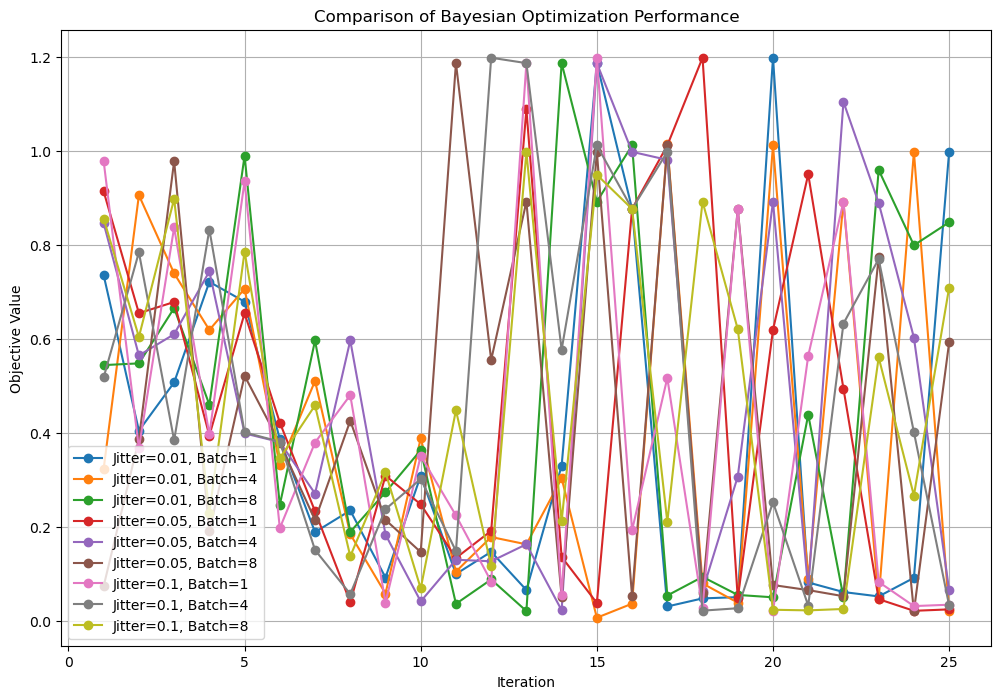


Summary of Results:
Jitter: 0.01, Batch Size: 1
Optimal RGB: [ 79.54131318  51.58210625 134.06261184], Optimal Value: 0.0307

Jitter: 0.01, Batch Size: 4
Optimal RGB: [ 73.88419369  45.68387423 132.26798444], Optimal Value: 0.0067

Jitter: 0.01, Batch Size: 8
Optimal RGB: [ 70.13581747  48.2006709  131.09439701], Optimal Value: 0.0209

Jitter: 0.05, Batch Size: 1
Optimal RGB: [ 76.98775865  45.44195455 136.06167959], Optimal Value: 0.0214

Jitter: 0.05, Batch Size: 4
Optimal RGB: [ 72.93113076  48.9584878  126.48446537], Optimal Value: 0.0227

Jitter: 0.05, Batch Size: 8
Optimal RGB: [ 70.56220536  45.22313873 133.61099802], Optimal Value: 0.0204

Jitter: 0.1, Batch Size: 1
Optimal RGB: [ 79.06635792  48.86550824 129.81289578], Optimal Value: 0.0201

Jitter: 0.1, Batch Size: 4
Optimal RGB: [ 78.97659687  48.51029132 133.94597892], Optimal Value: 0.0218

Jitter: 0.1, Batch Size: 8
Optimal RGB: [ 79.24368042  44.8806695  134.63636009], Optimal Value: 0.0224



In [20]:
# Target color
target_color = (75, 46, 131)

# Normalize the RGB values
normalized_target = np.array([c / 255 for c in target_color])

# Define the objective function
def objective_function(rgb_array):
    return np.array([
        np.linalg.norm(normalized_target - rgb) for rgb in rgb_array
    ]).reshape(-1, 1)  # GPyOpt expects a column vector

# Define the domain for RGB optimization (normalized [0, 1] for R, G, B)
bounds = [
    {'name': 'R', 'type': 'continuous', 'domain': (0, 1)},
    {'name': 'G', 'type': 'continuous', 'domain': (0, 1)},
    {'name': 'B', 'type': 'continuous', 'domain': (0, 1)}
]

# Function to run Bayesian Optimization with specified parameters
def run_bo(acquisition_jitter, batch_size, max_iter=20):
    optimizer = GPyOpt.methods.BayesianOptimization(
        f=objective_function,
        domain=bounds,
        acquisition_type='EI',  # Expected Improvement
        acquisition_jitter=acquisition_jitter,
        batch_size=batch_size,
        model_type='GP',
        kernel=GPy.kern.RBF(input_dim=3, lengthscale=0.2)
    )
    optimizer.run_optimization(max_iter=max_iter)

    # Collect results
    optimal_rgb = optimizer.x_opt * 255  # Scale back to original range
    optimal_value = optimizer.fx_opt
    return optimizer, optimal_rgb, optimal_value

# Parameters to test
acquisition_jitter_values = [0.01, 0.05, 0.1]
batch_sizes = [1, 4, 8]
max_iter = 20

# Store results
results = []

for jitter in acquisition_jitter_values:
    for batch_size in batch_sizes:
        optimizer, optimal_rgb, optimal_value = run_bo(
            acquisition_jitter=jitter,
            batch_size=batch_size,
            max_iter=max_iter
        )
        results.append({
            'jitter': jitter,
            'batch_size': batch_size,
            'optimal_rgb': optimal_rgb,
            'optimal_value': optimal_value,
            'optimizer': optimizer
        })

# Plot the results for comparison
plt.figure(figsize=(12, 8))
for result in results:
    jitter = result['jitter']
    batch_size = result['batch_size']
    optimizer = result['optimizer']
    plt.plot(range(1, len(optimizer.Y) + 1), optimizer.Y, marker="o", label=f"Jitter={jitter}, Batch={batch_size}")

plt.xlabel("Iteration")
plt.ylabel("Objective Value")
plt.title("Comparison of Bayesian Optimization Performance")
plt.legend()
plt.grid(True)
plt.show()

# Display summary of results
print("\nSummary of Results:")
for result in results:
    print(f"Jitter: {result['jitter']}, Batch Size: {result['batch_size']}")
    print(f"Optimal RGB: {result['optimal_rgb']}, Optimal Value: {result['optimal_value']:.4f}\n")
